# Tema 22 · Embeddings: representar cosas como vectores

Palabras, imágenes y sonidos convertidos en puntos de un espacio donde la cercanía significa algo.

Este cuaderno es el tema 22 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/22-embeddings-representar-cosas-como-vectores/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q sentence-transformers==6.2.0 umap-learn==0.5.12

# Teoría

## La pregunta

Escribes en un buscador «¿cómo me inscribo?». La respuesta que te sirve está en una página que dice «Pasos para registrarte en el curso». Las dos frases no comparten **ni una sola palabra**, y aun así cualquier persona ve que hablan de lo mismo. ¿Cómo puede verlo una computadora?

En el tema 21 convertiste el texto en números: cada palabra recibió un número de vocabulario y cada documento, un vector de conteos. Esos números sirven para clasificar, pero no saben nada del **significado**: para ellos, «inscribirse» y «registrarse» son tan distintas como «inscribirse» y «volcán». En este tema vas a construir otra representación, el **embedding**: un vector de unos cuantos números por cada palabra, frase o imagen, elegido de modo que **las cosas parecidas queden cerca**. Es la idea que está debajo de los buscadores, los sistemas de recomendación y los modelos de lenguaje de los temas que siguen.

En este tema vas a:

- ver por qué un vector **one-hot** no captura el significado y un embedding sí;
- entrenar desde cero, en PyTorch, embeddings de palabras con **skip-gram y muestreo negativo** sobre el *Quijote*;
- usar `nn.Embedding` como una tabla que se aprende y promediar embeddings para representar una frase;
- usar un modelo **preentrenado** para obtener embeddings de frases en español y armar un **buscador semántico**;
- sacar embeddings de **imágenes** con una red convolucional preentrenada y buscar las imágenes más parecidas;
- dibujar embeddings en un plano con **UMAP** y saber qué no se puede concluir de ese dibujo.

Necesitas el producto punto y la similitud coseno del tema 3, UMAP del tema 15, el bucle de entrenamiento de PyTorch del tema 18, las redes convolucionales del tema 20 y el *Quijote* tokenizado del tema 21.

## Actividad: el mapa de palabras

Aquí hay 300 palabras en español. Cada una es en realidad una lista de 50 números (su embedding), y el mapa es un dibujo aproximado de esas 50 dimensiones en dos. Toca una palabra, o elígela en la lista, y verás sus **cinco vecinas más cercanas** según la similitud coseno, calculada en tu navegador con los 50 números. Abajo, el panel de **analogías** suma y resta vectores: «rey − hombre + mujer» busca la palabra cuyo vector se parece más al resultado.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/22-embeddings-representar-cosas-como-vectores/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Toca «perro», después «lunes» y después «rojo». ¿Las vecinas son del mismo tema? ¿Están cerca en el mapa?
2. Busca una palabra cuyas vecinas queden **lejos** en el mapa: las líneas cruzan el dibujo. ¿Qué te dice eso del mapa?
3. Prueba las analogías de ejemplo. ¿Cuáles salen bien? Fíjate en «rey − hombre + mujer»: ¿la respuesta que esperabas sale primera?
4. Prueba «médico − hombre + mujer». ¿Qué profesión sale primero? ¿Por qué podría pasar eso?

El mapa es **una sombra** de 50 dimensiones en un plano, como las del tema 15: las vecinas de verdad se calculan con los 50 números, y el dibujo a veces las separa. Y las analogías son un truco llamativo que **funciona solo a veces**. Al final del tema vas a entender las dos cosas.

## Por qué un número por palabra no basta

La forma más directa de convertir palabras en vectores es la del tema 21: darle a cada palabra del vocabulario una posición y representarla con un vector lleno de ceros que tiene un 1 en su posición. Se llama vector **one-hot** («uno encendido»). Usemos la similitud coseno del tema 3 para ver qué tan parecidas son cuatro palabras así:

In [ ]:
import numpy as np

palabras = ["perro", "gato", "mesa", "silla"]
one_hot = np.eye(len(palabras))      # una fila por palabra
for p, v in zip(palabras, one_hot):
    print(f"{p:6s} {v}")


def coseno(a, b):
    """Similitud coseno (tema 3): producto punto entre las normas."""
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


print("perro y gato:", coseno(one_hot[0], one_hot[1]))
print("perro y mesa:", coseno(one_hot[0], one_hot[2]))

perro  [1. 0. 0. 0.]
gato   [0. 1. 0. 0.]
mesa   [0. 0. 1. 0.]
silla  [0. 0. 0. 1.]
perro y gato: 0.0
perro y mesa: 0.0


Con one-hot, **todas las parejas de palabras distintas tienen similitud 0**: dos vectores con el 1 en lugares distintos no comparten nada. «Perro» está tan lejos de «gato» como de «mesa». Además, con un vocabulario de 12 000 palabras cada vector tiene 12 000 números, casi todos ceros.

Imagina ahora que describimos cada palabra con unas pocas características inventadas por nosotros, con valores entre 0 y 1: ¿es un ser vivo?, ¿tiene patas?, ¿se usa en la casa?

In [ ]:
# Tres características a mano: ser vivo, tiene patas, se usa en casa
a_mano = np.array([
    [1.0, 0.9, 0.2],   # perro
    [1.0, 0.7, 0.5],   # gato
    [0.0, 0.9, 0.8],   # mesa
    [0.0, 0.7, 1.0],   # silla
])
print(f"perro y gato:  {coseno(a_mano[0], a_mano[1]):.2f}")
print(f"perro y mesa:  {coseno(a_mano[0], a_mano[2]):.2f}")
print(f"mesa y silla:  {coseno(a_mano[2], a_mano[3]):.2f}")

perro y gato:  0.96
perro y mesa:  0.59
mesa y silla:  0.97


Ahora sí: perro y gato se parecen mucho, mesa y silla también, y perro y mesa bastante menos (comparten tener patas). Eso es un **embedding**: un vector **denso** (casi sin ceros) y **corto** en el que la cercanía significa algo. El problema es que nadie puede escribir a mano características para 12 000 palabras. La idea de este tema es que **los números se aprenden de los datos**, y que las características aprendidas no tienen nombre: no hay una dimensión «ser vivo», sino 50 o 384 números que, juntos, ubican la palabra.

## Dime con quién andas: la hipótesis distribucional

¿De dónde sale el significado de una palabra, si la computadora solo ve texto? De sus **vecinas**. Si lees «tomé un vaso de *chicha* bien fría» y «la *chicha* de maní estaba dulce», aunque no conozcas la palabra adivinas que es una bebida: aparece en los mismos lugares que «jugo» o «refresco». Es la **hipótesis distribucional**: las palabras que aparecen en contextos parecidos tienen significados parecidos.

Vamos a usarla con el *Quijote*, el mismo libro del tema 21, con el mismo código para cargarlo:

In [ ]:
import re
import urllib.request
from collections import Counter
from pathlib import Path

# Don Quijote en el Proyecto Gutenberg (libro n.º 2000, dominio público).
# Se baja una sola vez y queda guardado en la carpeta «datos».
URL = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
archivo = Path("datos/quijote-pg2000.txt")
if not archivo.exists():
    archivo.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, archivo)

crudo = archivo.read_text(encoding="utf-8")
# El libro está entre dos marcas: se quitan la cabecera y el pie
marca = crudo.index("*** START OF THE PROJECT GUTENBERG EBOOK")
inicio = crudo.index("\n", marca) + 1
fin = crudo.index("*** END OF")
quijote = crudo[inicio:fin].strip()

tokens = re.findall(r"\w+", quijote.lower())
conteo = Counter(tokens)
print(f"{len(tokens):,} palabras, {len(conteo):,} distintas")

383,640 palabras, 22,950 distintas


Para cada palabra del texto, sus **palabras de contexto** son las que están a una distancia de hasta 2 posiciones, a la izquierda o a la derecha (la **ventana**). Cada pareja (palabra central, palabra de contexto) es un ejemplo:

In [ ]:
def pares_de_contexto(lista, ventana=2):
    """Parejas (central, contexto) a distancia de hasta `ventana`."""
    pares = []
    for i, central in enumerate(lista):
        for j in range(i - ventana, i + ventana + 1):
            if j != i and 0 <= j < len(lista):
                pares.append((central, lista[j]))
    return pares


frase = ["en", "un", "lugar", "de", "la", "mancha"]
# Solo las parejas en las que «lugar» es la palabra central
print([par for par in pares_de_contexto(frase) if par[0] == "lugar"])
print("Parejas de toda la frase:", len(pares_de_contexto(frase)))

[('lugar', 'en'), ('lugar', 'un'), ('lugar', 'de'), ('lugar', 'la')]
Parejas de toda la frase: 18


Con una frase de seis palabras ya salen 18 parejas; con el libro entero serían más de un millón y medio. Esas parejas son los datos de entrenamiento: no hace falta que nadie etiquete nada, porque el texto mismo dice qué palabras andan juntas.

## Skip-gram con muestreo negativo

El modelo **skip-gram** (de la familia Word2Vec, publicada por Mikolov y su equipo en 2013) aprende un vector por palabra con una tarea inventada: **dada una palabra, adivinar qué palabras aparecen a su alrededor**. La tarea en sí no nos importa. Lo que nos importa es que, para resolverla, el modelo tiene que darles vectores parecidos a las palabras que aparecen en contextos parecidos.

Cada palabra tiene **dos** vectores: uno para cuando es la central (*e*) y otro para cuando es el contexto (*c*). El modelo dice que una pareja es real con la probabilidad

$$P ( \text{pareja real} ) = \sigma ( {\mathbf{e}}_{\text{central}} \cdot {\mathbf{c}}_{\text{contexto}} )$$

donde σ es la sigmoide de la regresión logística (tema 8) y el punto es el producto punto. Si los dos vectores apuntan hacia el mismo lado, el producto punto es grande y la probabilidad, cercana a 1.

Si solo le mostráramos parejas reales, el modelo haría trampa: pondría todos los vectores iguales y diría «sí» siempre. Por eso, por cada pareja real se sortean 5 palabras al azar del vocabulario, que casi seguro no son contexto de verdad: son los **ejemplos negativos**, y el modelo debe darles probabilidad cercana a 0. Esto es el **muestreo negativo**. La pérdida es la entropía cruzada binaria del tema 8, escrita en dos partes:

- Para la pareja real queremos σ(*e* · *c*) cerca de 1, o sea, −ln σ(*e* · *c*) chico.
- Para cada negativa queremos σ(*e* · *c*) cerca de 0, o sea, 1 − σ(*e* · *c*) cerca de 1. Como 1 − σ(*z*) = σ(−*z*) (la sigmoide es simétrica), eso es pedir que −ln σ(−*e* · *c*) sea chico.

La pérdida suma esas dos cantidades. En el código, `logsigmoid(z)` calcula ln σ(*z*) de una sola vez (y sin errores de redondeo cuando σ es casi 0); en PyTorch, como en NumPy, `log` es el logaritmo natural, el ln del colegio.

Antes de entrenar, dos detalles prácticos:

- **Vocabulario.** Nos quedamos con las 3000 palabras más frecuentes; las demás aparecen muy pocas veces como para aprender algo de ellas.
- **Submuestreo.** Palabras como «de», «que» y «y» aparecen miles de veces y dicen poco de sus vecinas. Cada aparición de una palabra con frecuencia relativa *f* (la fracción del texto que ocupa) se conserva con probabilidad √(10⁻⁴ / *f*), o siempre, si eso pasa de 1. La idea: una palabra que ocupa menos de 1 de cada 10 000 palabras del texto (*f* menor que 10⁻⁴) se conserva siempre; una 100 veces más frecuente que ese umbral se conserva 1 de cada 10 veces (√(1/100) = 0,1). Así las palabras muy frecuentes se descartan casi siempre y las raras se quedan. El 10⁻⁴ y la raíz no salen de una teoría: son los valores que mejor funcionaron en el artículo original de Word2Vec.

In [ ]:
import torch
from torch import nn

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
rng = np.random.default_rng(0)

vocab = [p for p, _ in conteo.most_common(3000)]
indice = {p: i for i, p in enumerate(vocab)}
frec = np.array([conteo[p] for p in vocab]) / len(tokens)

# El texto como números, sin las palabras fuera del vocabulario
ids = np.array([indice[p] for p in tokens if p in indice])
# Submuestreo: las palabras muy frecuentes se descartan casi siempre
conservar = rng.random(len(ids)) < np.sqrt(1e-4 / frec[ids])
ids = ids[conservar]

# Todas las parejas a distancia 1 o 2, en los dos sentidos, sin bucle
# por palabra: si ids = [a, b, c, d] y d = 1, ids[:-1] = [a, b, c] e
# ids[1:] = [b, c, d], y juntos dan (a, b), (b, c), (c, d)
centrales, contextos = [], []
for d in (1, 2):
    centrales += [ids[:-d], ids[d:]]
    contextos += [ids[d:], ids[:-d]]
centrales = torch.tensor(np.concatenate(centrales))
contextos = torch.tensor(np.concatenate(contextos))
print(f"Quedan {len(ids):,} palabras y {len(centrales):,} parejas")

Quedan 112,989 palabras y 451,950 parejas


El modelo son dos tablas de vectores, una para cada papel. En PyTorch, una tabla así es una capa `nn.Embedding(n, d)`: guarda una matriz de *n* filas (una por palabra) y *d* columnas, y al darle números de palabra devuelve sus filas. Más abajo la miramos de cerca.

In [ ]:
class SkipGram(nn.Module):
    def __init__(self, n_palabras, dim):
        super().__init__()
        self.central = nn.Embedding(n_palabras, dim)
        self.contexto = nn.Embedding(n_palabras, dim)
        # Empiezan con números chicos al azar y en cero
        nn.init.uniform_(self.central.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.contexto.weight)

    def forward(self, c, x, negativos):
        e = self.central(c)                          # (lote, dim)
        # Producto punto con el contexto real: debe ser grande
        pos = (e * self.contexto(x)).sum(dim=1)      # (lote,)
        # Producto punto con los 5 negativos: debe ser chico.
        # unsqueeze(2) agrega un eje: e pasa a (lote, dim, 1).
        # @ multiplica una matriz por cada fila del lote:
        # (lote, 5, dim) @ (lote, dim, 1) -> (lote, 5, 1)
        neg = self.contexto(negativos) @ e.unsqueeze(2)
        neg = neg.squeeze(2)                         # quita el eje: (lote, 5)
        f = nn.functional.logsigmoid                 # f(z) = ln σ(z)
        return -(f(pos).mean() + f(-neg).sum(dim=1).mean())


modelo = SkipGram(len(vocab), dim=50).to(device)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.01)
# Los negativos se sortean con probabilidad proporcional a f^0,75
# (frecuencia elevada a 0,75), no a f: ver el texto de abajo
p_neg = torch.tensor(frec ** 0.75)
p_neg = p_neg / p_neg.sum()
g = torch.Generator().manual_seed(0)

for epoca in range(1, 6):
    orden = torch.randperm(len(centrales), generator=g)
    total = 0.0
    for k in range(0, len(orden), 1024):
        lote = orden[k:k + 1024]
        negativos = torch.multinomial(p_neg, 5 * len(lote),
                                      replacement=True, generator=g)
        negativos = negativos.view(len(lote), 5)
        optimizador.zero_grad()
        perdida = modelo(centrales[lote].to(device),
                         contextos[lote].to(device),
                         negativos.to(device))
        perdida.backward()
        optimizador.step()
        total += perdida.item() * len(lote)
    print(f"Época {epoca}: pérdida {total / len(orden):.3f}")

Época 1: pérdida 2.739
Época 2: pérdida 2.536
Época 3: pérdida 2.419
Época 4: pérdida 2.356
Época 5: pérdida 2.323


Los negativos no se sortean según la frecuencia pura *f*, sino según *f*<sup>0,75</sup>. Elevar a 0,75 achata un poco las diferencias: una palabra 100 veces más frecuente que otra sale como negativa unas 32 veces más (100<sup>0,75</sup> ≈ 32), no 100. Así las palabras muy frecuentes salen algo menos y las raras algo más. Como el 10⁻⁴ del submuestreo, el 0,75 es el valor que mejor funcionó en el artículo original.

La pérdida baja época tras época. Ahora la prueba de verdad: tomamos la tabla `central`, normalizamos cada fila para que mida 1 (así el producto punto **es** la similitud coseno) y buscamos las palabras más cercanas a algunas palabras del libro.

In [ ]:
E = modelo.central.weight.detach().cpu()
E = E / E.norm(dim=1, keepdim=True)          # cada fila mide 1


def vecinas(palabra, k=5):
    """Las k palabras del vocabulario más parecidas por coseno."""
    sim = E @ E[indice[palabra]]
    mejores = sim.argsort(descending=True)[1:k + 1]   # sin ella misma
    return [(vocab[i], round(sim[i].item(), 2)) for i in mejores]


for p in ["caballero", "ínsula", "gigantes", "oro", "cura", "libros"]:
    lista = ", ".join(f"{v} {s:.2f}" for v, s in vecinas(p, k=4))
    print(f"{p}: {lista}")

caballero: valeroso 0.65, valiente 0.59, poderoso 0.52, cristiano 0.52
ínsula: barataria 0.74, gobierno 0.60, gobernar 0.59, vasallos 0.59
gigantes: malandrines 0.58, molinos 0.57, hojas 0.48, aquellos 0.48
oro: traía 0.64, perlas 0.62, plata 0.62, blancas 0.61
cura: barbero 0.59, canónigo 0.56, carrasco 0.56, el 0.55
libros: caballerías 0.61, leído 0.55, componer 0.53, merecen 0.52


Nadie le dijo al modelo qué significa cada palabra, y aun así sus vecinas tienen sentido: «caballero» queda junto a «valeroso» y «valiente»; «ínsula» (la isla que Sancho sueña con gobernar) junto a «barataria», «gobierno» y «gobernar»; «gigantes» junto a «molinos»; «oro» junto a «perlas» y «plata»; y «cura» junto a «barbero» y «canónigo», personajes que hacen cosas parecidas en el libro. También hay ruido: «traía», «hojas» o «el» no se parecen en significado a sus palabras, solo aparecen a menudo cerca de ellas. Con un solo libro y cinco épocas, el modelo aprende lo que el *Quijote* permite; los modelos que usaremos más abajo aprendieron de muchísimo más texto.

### Un mapa de las palabras del *Quijote*

Cada palabra es ahora un punto en 50 dimensiones. Para mirarlas usamos UMAP, como en el tema 15 (si en Colab `import umap` da `ModuleNotFoundError`, ejecuta antes en una celda aparte `!pip install umap-learn`), con la métrica coseno, y marcamos cuatro grupos de palabras que elegimos nosotros entre las que el skip-gram ya junta (UMAP no sabe nada de los grupos).

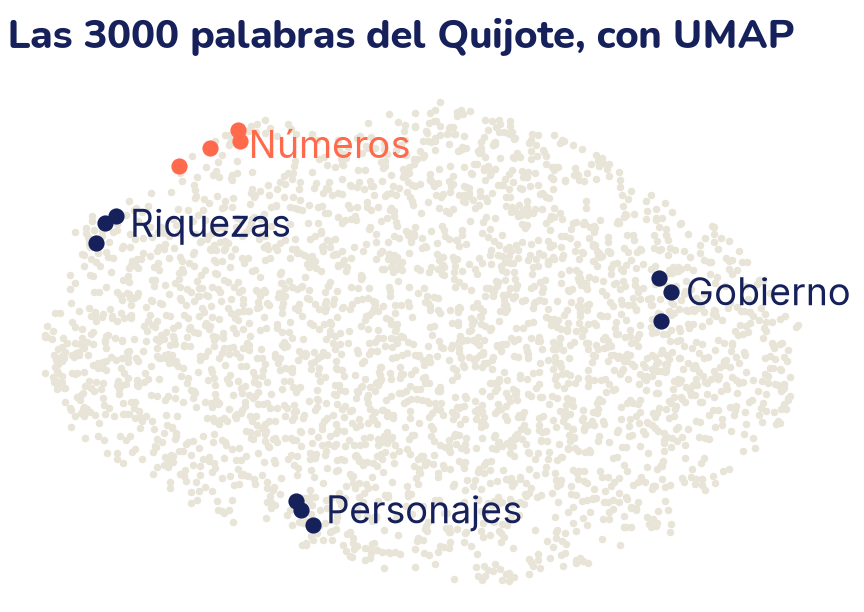

In [ ]:
import matplotlib.pyplot as plt
import umap

plano = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                  random_state=0, n_jobs=1).fit_transform(E.numpy())

# Solo para dibujar: la nube y cuatro grupos de palabras marcados
grupos = {
    "Números": ["tres", "cuatro", "seis", "mil"],
    "Personajes": ["cura", "barbero", "canónigo"],
    "Riquezas": ["oro", "plata", "perlas"],
    "Gobierno": ["ínsula", "gobierno", "vasallos"],
}
plt.scatter(plano[:, 0], plano[:, 1], s=4, color="C3")
for nombre, lista in grupos.items():
    # Un solo grupo va resaltado en coral
    color = "C1" if nombre == "Números" else "C0"
    xy = plano[[indice[p] for p in lista]]
    plt.scatter(xy[:, 0], xy[:, 1], s=30, color=color, zorder=3)
    # El nombre del grupo, un poco a la derecha de sus palabras
    x, y = np.median(xy, axis=0)
    plt.annotate(nombre, (x, y), xytext=(10, 0), color=color,
                 textcoords="offset points", va="center")
plt.axis("off")
plt.title("Las 3000 palabras del Quijote, con UMAP")
plt.show()

Las palabras de cada grupo quedaron juntas en el plano, aunque UMAP nunca vio los grupos. Pero no todas las agrupaciones salen tan limpias (elegimos estas a propósito), y valen las advertencias del tema 15: que los números queden cerca de las riquezas no significa nada, porque las distancias entre grupos lejanos no se conservan.

## `nn.Embedding`: una tabla que se aprende

`nn.Embedding` parece algo nuevo, pero es una capa lineal disfrazada. Multiplicar un vector one-hot por una matriz da exactamente la fila de la matriz donde está el 1 (es la multiplicación de matrices del tema 3). `nn.Embedding` se salta la multiplicación, que estaría llena de ceros, y va directo a la fila:

In [ ]:
tabla = modelo.central                       # nn.Embedding(3000, 50)
print("Forma de la tabla:", tuple(tabla.weight.shape))

i = indice["sancho"]
uno = torch.zeros(len(vocab))
uno[i] = 1.0                                 # «sancho» en one-hot
por_matriz = uno @ tabla.weight              # one-hot por la matriz
por_tabla = tabla(torch.tensor(i))           # buscar la fila
print("¿Iguales?", torch.allclose(por_matriz, por_tabla))

Forma de la tabla: (3000, 50)
¿Iguales? True


Por eso los pesos de `nn.Embedding` se entrenan con el descenso de gradiente, como los de cualquier otra capa. En cada paso, el gradiente solo es distinto de cero en las filas de las palabras que aparecieron en el lote. Con el descenso de gradiente simple, solo cambian esas filas; con Adam, que recuerda los pasos anteriores (su «momento»), las demás filas también pueden moverse un poco. Un modelo de lenguaje empieza siempre con una capa así, que convierte cada token en su vector.

### De palabras a frases: promediar

¿Y una frase? La forma más simple de convertir varias palabras en **un** vector es promediar sus vectores: es un **pooling** promedio, como el de las redes convolucionales del tema 20, pero a lo largo de las palabras en lugar de los píxeles.

In [ ]:
def vector_frase(frase):
    """Promedio de los vectores de las palabras que están en el vocabulario."""
    ids_frase = [indice[p] for p in re.findall(r"\w+", frase.lower())
                 if p in indice]
    v = E[ids_frase].mean(dim=0)
    return v / v.norm()


a = vector_frase("el valeroso caballero andante")
b = vector_frase("un caballero valiente y famoso")
c = vector_frase("comieron pan queso y vino")
print(f"caballero y caballero: {(a @ b).item():.2f}")
print(f"caballero y comida:    {(a @ c).item():.2f}")

caballero y caballero: 0.80
caballero y comida:    0.20


Las dos frases sobre caballeros tienen similitud 0,80 y la de la comida queda en 0,20, aunque solo compartan una palabra. El promedio funciona sorprendentemente bien para frases cortas, pero tiene un defecto grave: **ignora el orden**. «El perro mordió al cartero» y «el cartero mordió al perro» dan exactamente el mismo vector. Los modelos de frases modernos, como el que usamos a continuación, también terminan con un promedio, pero antes hacen pasar cada palabra por un **transformer** (tema 23), que mezcla la información de toda la frase y sí tiene en cuenta el orden.

## Embeddings de frases con un modelo preentrenado

Nuestro skip-gram aprendió de un solo libro de hace 400 años: no conoce «computadora» y su español es el de Cervantes. En la práctica se usan modelos ya entrenados con muchísimo texto. Usaremos [`paraphrase-multilingual-MiniLM-L12-v2`](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2), de la librería `sentence-transformers` (licencia Apache-2.0), que convierte una frase en cualquiera de unos 50 idiomas, incluido el español, en un vector de 384 números. Fue entrenado para que **dos frases que dicen lo mismo con otras palabras** queden cerca. La primera vez se descargan unos 470 MB. Si en Colab `from sentence_transformers import ...` da `ModuleNotFoundError`, ejecuta antes en una celda aparte `!pip install sentence-transformers`.

In [ ]:
from sentence_transformers import SentenceTransformer

nombre = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
frases_modelo = SentenceTransformer(nombre, device=device)

frases = [
    "¿Cómo me inscribo al curso?",
    "Quiero registrarme en las clases.",
    "Mañana va a llover en La Paz.",
    "El pronóstico anuncia tormenta para mañana.",
    "Mi perro duerme todo el día.",
    "El cachorro pasa la tarde durmiendo.",
]
V = frases_modelo.encode(frases, normalize_embeddings=True)
print("Forma:", V.shape)
similitud = V @ V.T            # cosenos: las filas ya miden 1
print(np.round(similitud, 2))

Forma: (6, 384)
[[ 1.    0.8  -0.04 -0.04 -0.11 -0.09]
 [ 0.8   1.   -0.02  0.01 -0.06 -0.07]
 [-0.04 -0.02  1.    0.36  0.06  0.11]
 [-0.04  0.01  0.36  1.    0.08  0.14]
 [-0.11 -0.06  0.06  0.08  1.    0.68]
 [-0.09 -0.07  0.11  0.14  0.68  1.  ]]


Inscribirse y registrarse tienen similitud 0,80, y el perro y el cachorro, 0,68. Las dos frases del clima quedan en 0,36: hablan del tiempo, pero una dice lluvia y la otra tormenta, y solo una nombra La Paz. Entre frases de temas distintos, las similitudes van de −0,11 a 0,14: casi nada. Dibujemos la matriz como un mapa de calor:

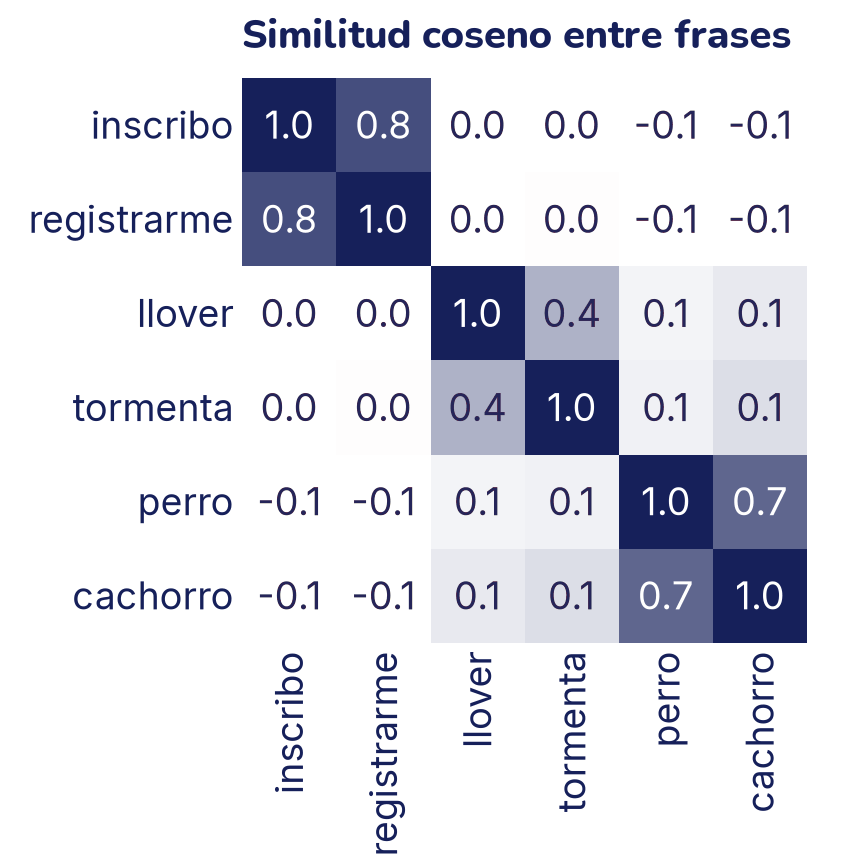

In [ ]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

cortas = ["inscribo", "registrarme", "llover", "tormenta", "perro",
          "cachorro"]
blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
plt.figure(figsize=(4.8, 4.8))
# Sumar 0 convierte los «-0.0» del redondeo en «0.0»
sns.heatmap(similitud, annot=np.round(similitud, 1) + 0, fmt=".1f",
            cmap=blanco_tinta, vmin=0, vmax=1, xticklabels=cortas,
            yticklabels=cortas, cbar=False, square=True)
plt.title("Similitud coseno entre frases")
plt.show()

Para comparar, la bolsa de palabras del tema 21 no ve ningún parecido entre las dos primeras frases:

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

bolsa = CountVectorizer().fit_transform(frases[:2]).toarray()
print("Bolsa de palabras:", coseno(bolsa[0], bolsa[1]))
print(f"Embeddings:        {similitud[0, 1]:.2f}")

Bolsa de palabras: 0.0
Embeddings:        0.80


Para la bolsa de palabras, las dos preguntas no tienen nada en común: no comparten ni una palabra. Para el modelo de frases, son casi la misma pregunta.

### Un buscador semántico

Con esto ya se puede armar un **buscador semántico**: un buscador que encuentra lo que **significa** lo mismo, no lo que tiene las mismas letras. Se calcula una sola vez el embedding de cada documento; ante una pregunta, se calcula el de la pregunta y se devuelven los documentos con mayor similitud coseno. Probemos con las frases de los capítulos 1 y 8 del *Quijote*, donde don Quijote enloquece con sus libros y pelea con los molinos:

In [ ]:
def capitulo(nombre, siguiente):
    """El texto de un capítulo, en una sola línea."""
    a = quijote.index(nombre)
    return " ".join(quijote[a:quijote.index(siguiente, a)].split())


texto = (capitulo("Capítulo primero", "Capítulo II")
         + " " + capitulo("Capítulo VIII", "Capítulo IX"))
# Partir en frases: después de un punto, punto y coma, «!» o «?»
oraciones = [f for f in re.split(r"(?<=[.;!?])\s+", texto)
             if 6 <= len(f.split()) <= 40]
D = frases_modelo.encode(oraciones, normalize_embeddings=True)
print(f"{len(oraciones)} frases, cada una con {D.shape[1]} números")


def buscar(pregunta, k=2):
    q = frases_modelo.encode(pregunta, normalize_embeddings=True)
    sim = D @ q
    for i in np.argsort(-sim)[:k]:
        print(f"  {sim[i]:.2f}  {oraciones[i][:68]}…")


for pregunta in ["Un hombre leyó tantos libros que perdió el juicio.",
                 "Ataca a unos gigantes que eran máquinas de viento."]:
    print(pregunta)
    buscar(pregunta)

135 frases, cada una con 384 números
Un hombre leyó tantos libros que perdió el juicio.
  0.64  y así, del poco dormir y del mucho leer, se le secó el celebro, de m…
  0.60  Llenósele la fantasía de todo aquello que leía en los libros, así de…
Ataca a unos gigantes que eran máquinas de viento.
  0.65  — Mire vuestra merced —respondió Sancho— que aquellos que allí se pa…
  0.60  — Peor será esto que los molinos de viento —dijo Sancho—.…


Las preguntas están escritas en el español de hoy y dicen las cosas de otra manera: «perdió el juicio» en lugar de «se le secó el celebro», «máquinas de viento» en lugar de «molinos». Aun así, la primera respuesta es la famosa frase «del poco dormir y del mucho leer, se le secó el celebro» («celebro» es la forma antigua de «cerebro»), y la segunda pregunta encuentra el momento en que Sancho le advierte a don Quijote que aquellos no son gigantes, sino molinos de viento. Así funcionan los buscadores semánticos: un embedding por documento, calculado una vez, y un producto punto por cada pregunta.

### Analogías y sus límites

Con buenos embeddings pasa algo curioso: las **diferencias** entre vectores también parecen tener significado. El vector que va de «hombre» a «mujer» se parece al que va de «rey» a «reina». Si eso es cierto, rey − hombre + mujer debería caer cerca de reina. Probémoslo con el modelo de frases, dándole palabras sueltas:

In [ ]:
lista = ("rey reina hombre mujer príncipe princesa padre madre tío tía "
         "París Francia Roma Italia Lima Perú Santiago Chile Madrid "
         "España caminar caminó comer comió").split()
W = frases_modelo.encode(lista, normalize_embeddings=True)
pos = {p: i for i, p in enumerate(lista)}


def analogia(a, b, c, k=3):
    """Las palabras más cercanas a a − b + c (sin a, b ni c)."""
    v = W[pos[a]] - W[pos[b]] + W[pos[c]]
    sim = W @ (v / np.linalg.norm(v))
    orden = [i for i in np.argsort(-sim) if lista[i] not in (a, b, c)]
    return [(lista[i], round(float(sim[i]), 2)) for i in orden[:k]]


for a, b, c in [("rey", "hombre", "mujer"), ("París", "Francia", "Italia"),
                ("caminó", "caminar", "comer")]:
    lista_r = ", ".join(f"{p} {s:.2f}" for p, s in analogia(a, b, c))
    print(f"{a} − {b} + {c} → {lista_r}")

rey − hombre + mujer → reina 0.82, tía 0.78, princesa 0.69
París − Francia + Italia → Roma 0.78, Santiago 0.67, España 0.63
caminó − caminar + comer → tío 0.69, comió 0.69, hombre 0.67


La primera sale como se esperaba, aunque «tía» queda cerca de «reina». La de las capitales también. La tercera, que busca el pasado de «comer», falla: «tío» queda primera y «comió», segunda, con la misma similitud redondeada. Las analogías salen bien con relaciones muy frecuentes en los textos (masculino y femenino, país y capital) y mal con muchas otras. Además, la función hace una pequeña trampa: deja fuera las palabras de la pregunta. Sin eso, la respuesta suele ser una de ellas: para «París − Francia + Italia», la palabra más cercana es «Italia».

En la actividad, con los vectores comprimidos a 50 números y otras 300 palabras alrededor, «rey − hombre + mujer» da primero «tía» y «reina» queda segunda: comprimir también tiene un costo. Toma las analogías como una señal de que el espacio tiene cierta estructura, no como una regla.

## Embeddings de imágenes

La misma idea sirve para imágenes. Una red convolucional entrenada para clasificar transforma la imagen capa por capa, y justo antes de la capa final que decide la clase tiene un vector que **resume** la imagen. Ese vector de la **penúltima capa** es un embedding: dos fotos que la red «ve» parecidas tienen vectores cercanos, aunque sus píxeles sean distintos.

Usaremos `resnet18`, una CNN de `torchvision` entrenada con ImageNet (1,2 millones de fotos de 1000 clases). Sus pesos se descargan la primera vez (47 MB; el código de torchvision tiene licencia BSD-3 y los pesos vienen de ImageNet, que permite su uso para investigación y educación). Su última capa, `fc`, convierte 512 números en 1000 puntajes; si la reemplazamos por `nn.Identity()`, que deja pasar su entrada sin cambios, la red devuelve el embedding de 512 números.

La probaremos con 1000 imágenes de prueba de FashionMNIST, el mismo dataset de los temas 18 a 20. ResNet espera fotos en color de tres canales, normalizadas con la media y la desviación de ImageNet; nuestras imágenes son grises de 28 × 28, así que repetimos el canal tres veces y las agrandamos a 64 × 64. Es una red pensada para fotos de objetos, no para siluetas de ropa: veamos si igual sirve.

In [ ]:
from torchvision import datasets, models

prueba = datasets.FashionMNIST(root="datos", train=False, download=True)
NOMBRES = ["Polera", "Pantalón", "Chompa", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
elegidas = torch.randperm(len(prueba), generator=g)[:1000]
imagenes = prueba.data[elegidas].float() / 255     # (1000, 28, 28)
clases = prueba.targets[elegidas].numpy()

red = models.resnet18(weights="DEFAULT")
red.fc = nn.Identity()           # sin la capa final: devuelve 512 números
red = red.to(device).eval()

media = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
desv = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
partes = []
with torch.no_grad():
    for k in range(0, len(imagenes), 100):
        x = imagenes[k:k + 100].unsqueeze(1).repeat(1, 3, 1, 1)
        # Agranda a 64 × 64: cada píxel nuevo es un promedio de sus vecinos
        x = nn.functional.interpolate(x, size=64, mode="bilinear")
        x = ((x - media) / desv).to(device)
        partes.append(red(x).cpu())
F = torch.cat(partes)
F = (F / F.norm(dim=1, keepdim=True)).numpy()
print("Embeddings de las imágenes:", F.shape)

Embeddings de las imágenes: (1000, 512)


¿Sirven? Una prueba simple, la del tema 15: para cada imagen, buscar su vecina más cercana y ver si es de la misma clase. Las clases no se usaron para hacer los embeddings, solo para revisarlos. Comparamos con lo que pasa si buscamos las vecinas directamente con los 784 píxeles.

In [ ]:
from sklearn.neighbors import NearestNeighbors


def vecina_igual(X, y):
    """Fracción de puntos cuya vecina más cercana es de su misma clase."""
    nn_ = NearestNeighbors(n_neighbors=2, metric="cosine").fit(X)
    i = nn_.kneighbors(X, return_distance=False)[:, 1]
    return np.mean(y[i] == y)


pixeles = imagenes.reshape(len(imagenes), -1).numpy()
print(f"Con los 784 píxeles:        {vecina_igual(pixeles, clases):.1%}")
print(f"Con los 512 de la resnet18: {vecina_igual(F, clases):.1%}")

Con los 784 píxeles:        74.3%
Con los 512 de la resnet18: 72.9%


Con los píxeles, la vecina más cercana es de la misma clase el 74,3 % de las veces; con la resnet18, el 72,9 %. **No mejora.** No es que la red sea mala: aprendió con fotos en color de animales, vehículos y objetos, y nuestras prendas son siluetas grises de 28 × 28 agrandadas. Sus 512 números describen lo que distingue a las fotos de ImageNet, y eso no es lo que separa una camisa de una chompa. Un embedding preentrenado sirve cuando sus datos de entrenamiento se parecen a los tuyos; en el tema 26 vas a reutilizar modelos de visión con fotos para los que sí fueron pensados.

### Una CNN entrenada con prendas

Probemos con una red que sí vio prendas: la CNN del tema 20, con una capa más. Después de las convoluciones agregamos una capa `nn.Linear` de 64 neuronas, seguida de ReLU, antes de la capa de salida. Esas 64 neuronas serán nuestro embedding. La entrenamos para clasificar, con 10 000 imágenes de entrenamiento y solo 3 épocas para que corra rápido, y después le cortamos la última capa: `cnn[:-1]` es la misma red sin su última capa.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

entrenamiento = datasets.FashionMNIST(root="datos", train=True,
                                      download=True)
idx_ent = torch.randperm(len(entrenamiento), generator=g)[:10000]
x_ent = entrenamiento.data[idx_ent].float() / 255
m_px, d_px = x_ent.mean(), x_ent.std()
x_ent = ((x_ent - m_px) / d_px).unsqueeze(1)
cargador = DataLoader(TensorDataset(x_ent, entrenamiento.targets[idx_ent]),
                      batch_size=64, shuffle=True,
                      generator=torch.Generator().manual_seed(0))

torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),                              # (16, 14, 14)
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),                              # (32, 7, 7)
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64), nn.ReLU(),         # el embedding
    nn.Linear(64, 10),                            # la clase
).to(device)
optimizador = torch.optim.Adam(cnn.parameters(), lr=1e-3)
for epoca in range(3):
    cnn.train()
    for x, y in cargador:
        optimizador.zero_grad()
        perdida = nn.functional.cross_entropy(cnn(x.to(device)),
                                              y.to(device))
        perdida.backward()
        optimizador.step()

cnn.eval()
with torch.no_grad():
    x = ((imagenes - m_px) / d_px).unsqueeze(1).to(device)
    acierta = (cnn(x).argmax(dim=1).cpu().numpy() == clases).mean()
    C = cnn[:-1](x).cpu()                 # sin la última capa: 64 números
C = (C / C.norm(dim=1, keepdim=True)).numpy()
print(f"La CNN clasifica bien el {acierta:.1%} de las 1000 imágenes")
print(f"Con los 64 de la CNN:       {vecina_igual(C, clases):.1%}")

La CNN clasifica bien el 82.8% de las 1000 imágenes
Con los 64 de la CNN:       82.6%


Esta CNN clasifica bien el 82,8 % de las 1000 imágenes, que no vio al entrenar. Y sus 64 números sirven como embedding: la vecina más cercana es de la misma clase el 82,6 % de las veces, contra el 74,3 % de los píxeles y el 72,9 % de la resnet18. Una red entrenada con **tus** datos aprende a juntar lo que tu problema necesita juntar. Dibujemos esos embeddings con UMAP; los bolsos van en coral:

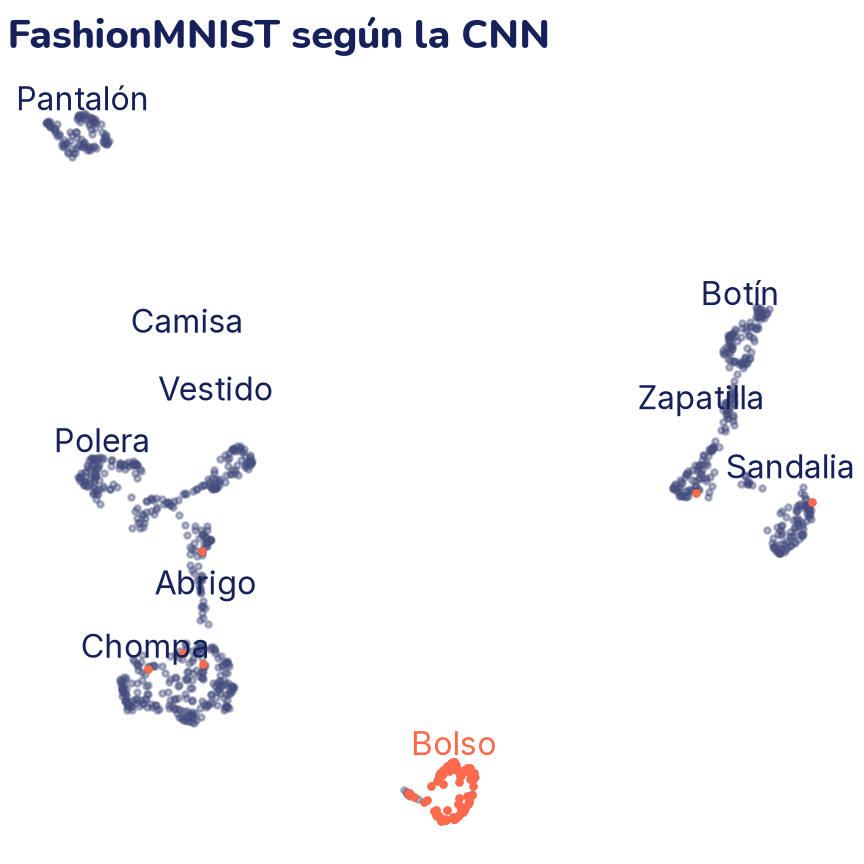

In [ ]:
mapa = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                 random_state=0, n_jobs=1).fit_transform(C)

plt.figure(figsize=(4.8, 4.8))
plt.scatter(mapa[:, 0], mapa[:, 1], s=6, color="C2", alpha=0.4)
bolsos = mapa[clases == NOMBRES.index("Bolso")]
plt.scatter(bolsos[:, 0], bolsos[:, 1], s=6, color="C1")
# Solo para dibujar: el nombre de cada clase va sobre la mayoría
# de sus puntos; si choca con otro nombre, se sube hasta que no choque
ancho, alto = np.ptp(mapa, axis=0) * [0.22, 0.06]
puestos = []
for c, nombre in enumerate(NOMBRES):
    x = np.median(mapa[clases == c, 0])
    y = np.percentile(mapa[clases == c, 1], 90)
    while any(abs(x - a) < ancho and abs(y - b) < alto
              for a, b in puestos):
        y += alto
    puestos.append((x, y))
    plt.text(x, y, nombre, fontsize=13, ha="center", va="bottom",
             color="C1" if nombre == "Bolso" else "C0")
plt.axis("off")
plt.title("FashionMNIST según la CNN")
plt.show()

El mapa repite lo que viste en los temas 18 y 20: el calzado por un lado, la ropa de la parte de arriba por otro, y la camisa mezclada con todo lo que tiene mangas (su nombre quedó arriba porque sus puntos están desparramados). Los pantalones y los bolsos son islas. Unos pocos bolsos caen lejos de los suyos: son imágenes que la CNN confunde.

Y ahora el buscador de imágenes: para tres imágenes de consulta, sus cuatro vecinas más cercanas por coseno, con los embeddings de la CNN.

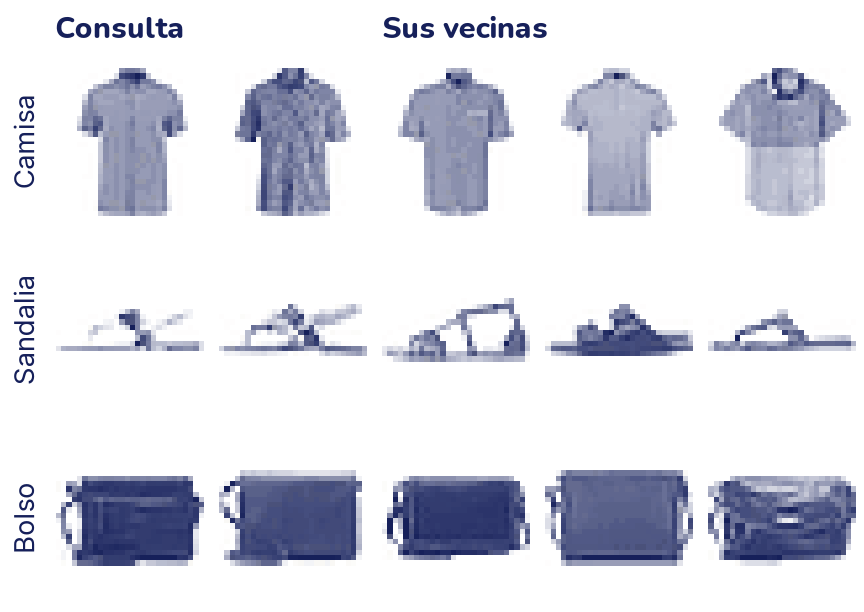

In [ ]:
# La primera camisa, sandalia y bolso de las 1000 imágenes
consultas = [np.flatnonzero(clases == c)[0] for c in (6, 5, 8)]
# Solo para dibujar: cada consulta con sus 4 vecinas, en tinta
tinta = LinearSegmentedColormap.from_list("tinta", ["white", "C0"])
fig, ejes = plt.subplots(3, 5, figsize=(4.8, 3.4))
for fila, q in enumerate(consultas):
    sim = C @ C[q]
    cercanas = np.argsort(-sim)[1:5]           # sin ella misma
    for col, k in enumerate([q, *cercanas]):
        eje = ejes[fila, col]
        eje.imshow(imagenes[k], cmap=tinta)
        eje.set_xticks([])
        eje.set_yticks([])
        eje.spines[:].set_visible(False)       # sin marco
    ejes[fila, 0].set_ylabel(NOMBRES[clases[q]], fontsize=11)
ejes[0, 0].set_title("Consulta", fontsize=12)
ejes[0, 2].set_title("Sus vecinas", fontsize=12)
plt.show()

Las vecinas no solo son de la misma clase: también se parecen en la forma (manga corta, tiras finas, bolsos rectangulares con asa). Así funciona un buscador de imágenes por parecido: un embedding por imagen y la similitud coseno.

### Y el sonido

Con el audio pasa lo mismo, y lo verás en el tema 28: un sonido se convierte primero en una imagen de sus frecuencias a lo largo del tiempo (un espectrograma), y una red entrenada con muchos sonidos lo resume en un vector. Dos grabaciones de la misma palabra, o de la misma canción, quedan cerca. Con embeddings de texto, de imágenes y de audio, «buscar lo parecido» es siempre lo mismo: calcular vectores y comparar cosenos.

## Lo que los embeddings aprenden de más: sesgos

Los embeddings aprenden **todo** lo que hay en sus datos, incluidos los prejuicios. Si en los textos de entrenamiento «enfermera» aparece más con palabras femeninas e «ingeniero» con masculinas, sus vectores lo reflejan, aunque no exista ninguna razón para que una profesión tenga género. En la actividad viste que «médico − hombre + mujer» da primero «enfermera». Eso importa: un buscador de currículums o un sistema que recomienda carreras construido sobre esos vectores puede repetir y amplificar la desigualdad. En el ejercicio 3 vas a medir un sesgo así, y en el tema 30 volveremos a la pregunta de cómo detectarlo y reducirlo.

## Lo que aprendiste y lo que sigue

- Un vector **one-hot** hace que todas las palabras distintas estén igual de lejos. Un **embedding** es un vector corto y denso en el que la cercanía significa parecido.
- Según la **hipótesis distribucional**, el significado sale del contexto. **Skip-gram con muestreo negativo** aprende vectores que predicen las palabras vecinas y distinguen las parejas reales de las sorteadas al azar.
- `nn.Embedding` es una tabla que se aprende: equivale a multiplicar un one-hot por una matriz. **Promediar** los vectores de las palabras da un vector para la frase, aunque pierde el orden.
- Los modelos **preentrenados** dan embeddings de frases (`sentence-transformers`) y de imágenes (la penúltima capa de una CNN). Con la **similitud coseno** se arma un buscador semántico.
- **UMAP** dibuja los embeddings en un plano, pero el plano distorsiona. Las **analogías** funcionan solo a veces, y los embeddings heredan los **sesgos** de sus datos.

En el tema 23 vas a ver la pieza que falta: la **atención**, que deja que el vector de cada palabra cambie según las demás palabras de la frase. Es lo que convierte una tabla de embeddings en un transformer.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `coseno`, `vocab`, `indice`, `E`, `vecinas`, `modelo` (el skip-gram), `frases_modelo` (el modelo de frases), `imagenes`, `clases`, `C` (los embeddings de la CNN), `mapa` y `vecina_igual`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. El coseno a mano

Tres vectores: **a** = (1, 2, 2), **b** = (2, 1, 2) y **c** = (−1, −2, −2).

1. Calcula sin computadora el producto punto y la similitud coseno entre **a** y **b**, y entre **a** y **c**.
2. ¿Cuál es la similitud coseno entre **a** y 2**a** = (2, 4, 4)? ¿Y su producto punto?
3. Comprueba todo con la función `coseno` de la teoría.

<details>
<summary>Respuesta</summary>

1. **a** · **b** = 2 + 2 + 4 = 8. Los dos vectores miden √(1 + 4 + 4) = 3, así que el coseno es 8 / 9 ≈ **0,89**: apuntan casi hacia el mismo lado. **a** · **c** = −1 − 4 − 4 = −9 y el coseno es −9 / 9 = **−1**: **c** es **a** dado vuelta.
2. El coseno entre **a** y 2**a** es **1**: apuntan exactamente hacia el mismo lado, aunque uno mida el doble. El producto punto, en cambio, se duplica: 2 · 9 = **18**. Por eso para comparar embeddings se usa el coseno (o se normalizan los vectores antes): solo importa la **dirección**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
a = np.array([1, 2, 2])
b = np.array([2, 1, 2])
c = np.array([-1, -2, -2])
print(f"a·b = {a @ b},  coseno(a, b) = {coseno(a, b):.2f}")
print(f"a·c = {a @ c},  coseno(a, c) = {coseno(a, c):.2f}")
print(f"a·2a = {a @ (2 * a)}, coseno(a, 2a) = {coseno(a, 2 * a):.2f}")

### 2. One-hot contra embeddings en un clasificador

Abajo hay 18 frases cortas **sintéticas** (las escribimos para este ejercicio) de tres temas, y otras 9 para probar, escritas a propósito con palabras distintas. Entrena una regresión logística (tema 8) de dos maneras:

- con la **bolsa de palabras** de cada frase (`CountVectorizer(binary=True)`: es la suma de los vectores one-hot de sus palabras);
- con el **embedding** de cada frase del modelo multilingüe.

Compara la exactitud en las 9 frases de prueba. Cuenta también cuántas palabras de cada frase de prueba estaban en el vocabulario de entrenamiento.

In [ ]:
from sklearn.linear_model import LogisticRegression

entrenamiento_frases = [
    ("Hoy hace mucho frío en la ciudad", "clima"),
    ("Va a llover toda la tarde", "clima"),
    ("El sol quema al mediodía", "clima"),
    ("Se viene una tormenta con granizo", "clima"),
    ("Hay neblina en la carretera", "clima"),
    ("El viento sopla fuerte esta noche", "clima"),
    ("La sopa de maní está deliciosa", "comida"),
    ("Comimos salteñas en el desayuno", "comida"),
    ("El pan recién horneado huele rico", "comida"),
    ("Preparé arroz con pollo", "comida"),
    ("Este postre lleva mucho azúcar", "comida"),
    ("La fruta del mercado está fresca", "comida"),
    ("El delantero metió dos goles", "deporte"),
    ("Entrenamos básquet todos los martes", "deporte"),
    ("El equipo ganó el campeonato", "deporte"),
    ("Corrí cinco kilómetros en el parque", "deporte"),
    ("El árbitro pitó un penal", "deporte"),
    ("Nadamos en la piscina del colegio", "deporte"),
]
prueba_frases = [
    ("Mañana amanecerá nublado y helado", "clima"),
    ("Anuncian chubascos para el fin de semana", "clima"),
    ("Qué calor tan sofocante", "clima"),
    ("Me encantan las empanadas de queso", "comida"),
    ("La cena estuvo sabrosa", "comida"),
    ("Cocinaremos fideos con carne", "comida"),
    ("La selección venció tres a uno", "deporte"),
    ("Me inscribí en un torneo de ajedrez", "deporte"),
    ("El ciclista llegó primero a la meta", "deporte"),
]

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_ent = [t for t, _ in entrenamiento_frases]
y_ent = [e for _, e in entrenamiento_frases]
X_pru = [t for t, _ in prueba_frases]
y_pru = np.array([e for _, e in prueba_frases])

# Bolsa de palabras: un 1 por cada palabra presente (suma de one-hot)
bolsa = CountVectorizer(binary=True).fit(X_ent)
# .A1 convierte el resultado en un arreglo plano de NumPy
print("Palabras conocidas por frase:",
      bolsa.transform(X_pru).sum(axis=1).A1)
clf = LogisticRegression(max_iter=1000)
clf.fit(bolsa.transform(X_ent), y_ent)
acierto = np.mean(clf.predict(bolsa.transform(X_pru)) == y_pru)
print(f"Bolsa de palabras: {acierto:.0%}")

# Embeddings de frases
V_ent = frases_modelo.encode(X_ent, normalize_embeddings=True)
V_pru = frases_modelo.encode(X_pru, normalize_embeddings=True)
clf = LogisticRegression(max_iter=1000).fit(V_ent, y_ent)
pred = clf.predict(V_pru)
print(f"Embeddings:        {np.mean(pred == y_pru):.0%}")
for frase, p, e in zip(X_pru, pred, y_pru):
    if p != e:
        print(f"Error: «{frase}» -> {p} (era {e})")

<details>
<summary>Respuesta</summary>

La bolsa de palabras acierta solo 3 de las 9 frases (33 %, lo mismo que adivinar al azar entre tres temas). Las frases de prueba tienen entre 0 y 3 palabras conocidas, y todas son palabras que no dicen nada del tema («el», «la», «de», «en», «con», «un»): para el clasificador, «Qué calor tan sofocante» es una fila de ceros. Con embeddings acierta 8 de 9 (89 %), aunque nunca vio «nublado», «empanadas» ni «ciclista»: el modelo de frases ya sabe que «sabrosa» está cerca de «deliciosa» y «torneo» cerca de «campeonato». Su único error es la frase de los chubascos, que tomó por comida. Es la ventaja de un embedding: lo que se aprende de una palabra sirve para sus vecinas.

</details>

### 3. Un sesgo de género

En la teoría y en la actividad viste que la dirección que va de «hombre» a «mujer» tiene significado. Úsala para medir un sesgo:

1. Calcula con el modelo de frases el vector **g** = mujer − hombre y normalízalo.
2. Para cada palabra de esta lista, que en español sirve igual para hombres y mujeres, calcula el producto punto de su embedding normalizado con **g**: piloto, chef, líder, policía, juez, periodista, cantante, estudiante, modelo. Un valor positivo dice que la palabra queda más del lado de «mujer»; uno negativo, del lado de «hombre».
3. Como referencia, calcula lo mismo para «él» y «ella».
4. Prueba también la analogía «médico − hombre + mujer» con estas palabras: médico, médica, enfermero, enfermera, hombre, mujer.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
pares = "hombre mujer él ella".split()
neutras = ("piloto chef líder policía juez periodista cantante "
           "estudiante modelo").split()
G = frases_modelo.encode(pares + neutras, normalize_embeddings=True)
genero = G[1] - G[0]                # mujer − hombre
genero = genero / np.linalg.norm(genero)
for p, v in zip(pares[2:] + neutras, G[2:]):
    print(f"{p:10s} {v @ genero:+.2f}")

# La analogía médico − hombre + mujer, paso a paso
lista = "médico médica enfermero enfermera hombre mujer".split()
W = frases_modelo.encode(lista, normalize_embeddings=True)
v = W[0] - W[4] + W[5]
sim = W @ (v / np.linalg.norm(v))
for i in np.argsort(-sim):
    if lista[i] not in ("médico", "hombre", "mujer"):
        print(f"médico − hombre + mujer ≈ {lista[i]:10s} {sim[i]:.2f}")

<details>
<summary>Respuesta</summary>

«él» queda del lado de «hombre» (−0,14) y «ella» del lado de «mujer» (+0,34), como se esperaba. Pero palabras que en español sirven para los dos también se inclinan: «chef» (−0,29), «piloto» (−0,27) y «líder» (−0,25) quedan del lado de «hombre», incluso más que el propio «él»; «estudiante» y «modelo» quedan apenas del lado de «mujer» (+0,06 y +0,07). Nadie programó eso: el modelo lo aprendió de los textos con que se entrenó, donde esas palabras aparecían más junto a hombres o a mujeres.

En la analogía, «médica» sale primera (0,76), pero «enfermera» queda casi empatada (0,75). En la actividad, con los vectores comprimidos a 50 números, «enfermera» llega a salir primera. Un sistema que use estos vectores, por ejemplo para ordenar postulantes a un trabajo, podría repetir esas asociaciones sin que nadie lo note.

</details>

### 4. La tabla de `nn.Embedding`

1. ¿Cuántos parámetros entrenables tiene el modelo skip-gram de la teoría? Calcúlalo a mano y compruébalo.
2. Un lote de 4 frases, cada una con 7 números de palabra, entra a `modelo.central`. ¿Qué forma tiene la salida? ¿Y si después promedias a lo largo de las palabras?
3. ¿Qué pasa si le das a la tabla el número 3000?

<details>
<summary>Respuesta</summary>

1. Dos tablas de 3000 filas por 50 columnas: 2 · 3000 · 50 = **300 000** parámetros. Son los mismos pesos que tendrían dos capas `nn.Linear(3000, 50)` sin sesgo que recibieran vectores one-hot; la diferencia es que `nn.Embedding` no hace las multiplicaciones por cero.
2. La salida es (4, 7, 50): un vector de 50 números por cada palabra de cada frase. Al promediar con `mean(dim=1)` queda (4, 50): un vector por frase.
3. Las filas van de 0 a 2999, así que 3000 no existe y PyTorch da un error. Es el mismo problema que el `<UNK>` del tema 21: el modelo solo conoce las palabras de su tabla.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
total = sum(p.numel() for p in modelo.parameters())
print(f"Parámetros del skip-gram: {total:,}")

lote = torch.randint(0, 3000, (4, 7), generator=g)
salida = modelo.central(lote)
print("Salida:", tuple(salida.shape))
print("Promedio por frase:", tuple(salida.mean(dim=1).shape))
modelo.central(torch.tensor([3000]))

### 5. Una palabra que el *Quijote* no conoce

Llama a `vecinas("computadora")`. ¿Qué pasa y por qué? Después busca con el modelo de frases cuál de estas palabras se parece más a «computadora»: laptop, ordenador, teclado, caballo, molino.

<details>
<summary>Respuesta</summary>

«computadora» no está en el *Quijote*, así que no tiene fila en la tabla y el diccionario `indice` no la encuentra:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
vecinas("computadora")

<details>
<summary>Respuesta (sigue)</summary>

El modelo de frases, en cambio, no trabaja con palabras enteras sino con **pedazos de palabras** (como el BPE del tema 21), así que puede armar un vector para cualquier palabra, aunque nunca la haya visto completa:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
otras = ["laptop", "ordenador", "teclado", "caballo", "molino"]
q = frases_modelo.encode("computadora", normalize_embeddings=True)
O = frases_modelo.encode(otras, normalize_embeddings=True)
for p, s in sorted(zip(otras, O @ q), key=lambda t: -t[1]):
    print(f"{p:10s} {s:.2f}")

<details>
<summary>Respuesta (sigue)</summary>

«ordenador» (la palabra que se usa en España para computadora) tiene similitud 0,99: es casi un sinónimo. Le siguen «laptop» (0,78) y «teclado» (0,55), y muy abajo «molino» y «caballo». El modelo de frases nunca tuvo un problema de palabra desconocida.

</details>

### 6. ¿Cuánto distorsiona el mapa?

El mapa de UMAP de las prendas parecía separar bien las clases. Mídelo: calcula `vecina_igual` con los 64 números de la CNN (`C`) y con las 2 coordenadas del mapa (`mapa`). Haz lo mismo con un PCA a 2 dimensiones de `C`. ¿Qué se pierde al pasar a 2 dimensiones, y qué método pierde más?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.decomposition import PCA

plano_pca = PCA(n_components=2).fit_transform(C)
print(f"64 dimensiones: {vecina_igual(C, clases):.1%}")
print(f"UMAP a 2:       {vecina_igual(mapa, clases):.1%}")
print(f"PCA a 2:        {vecina_igual(plano_pca, clases):.1%}")

<details>
<summary>Respuesta</summary>

Con las 64 dimensiones, la vecina más cercana es de la misma clase el 82,6 % de las veces; en el mapa de UMAP, el 70,7 %; con PCA a 2 dimensiones, el 52,0 %. Al pasar a dos dimensiones se pierden vecindarios. UMAP conserva bastante más que PCA, porque busca justamente conservar los vecinos, pero ninguno conserva todo. Por eso las vecinas de verdad se buscan con todas las dimensiones, como en la actividad, y el mapa sirve solo para mirar.

</details>

## Mini-proyecto: un buscador de preguntas frecuentes

Vas a construir un buscador que responde preguntas escritas con tus propias palabras. Usa las preguntas frecuentes de un **club de robótica imaginario** (las escribimos nosotros; no son de ninguna institución real), o mejor aún, escribe las de tu colegio o de un club que conozcas.

In [ ]:
faq = [
    ("¿Cómo me inscribo en el club?",
     "Llena el formulario de inscripción en la secretaría del colegio."),
    ("¿Cuánto cuesta participar?",
     "Participar es gratis; solo pedimos que traigas tu cuaderno."),
    ("¿Qué días se reúne el club?",
     "Nos reunimos los martes y jueves de 15:00 a 17:00."),
    ("¿Necesito saber programar?",
     "No. Empezamos desde cero con bloques y después Python."),
    ("¿Puedo llevar mi propia computadora?",
     "Sí, pero el club presta computadoras a quien no tenga."),
    ("¿Hay un límite de edad?",
     "El club es para estudiantes de 12 a 18 años."),
    ("¿Dónde queda el laboratorio?",
     "En el segundo piso del bloque B, al lado de la biblioteca."),
    ("¿Qué pasa si falto a una sesión?",
     "Avísale a tu tutor; las guías quedan en la carpeta compartida."),
]

1. Calcula una sola vez el embedding de cada pregunta frecuente, normalizado.
2. Escribe una función `responder(pregunta)` que calcule el embedding de la pregunta, busque la pregunta frecuente más parecida por coseno y devuelva su respuesta junto con la similitud.
3. Pruébala con preguntas escritas de otra forma, sin repetir palabras: «quiero registrarme», «¿es pagado?», «no sé nada de código», «¿en qué aula es?».
4. Pruébala con una pregunta que **no** está en la lista, como «¿venden uniformes?». ¿Qué responde? Agrega un **umbral**: si la mejor similitud no llega a, por ejemplo, 0,35, que diga «No encontré una respuesta; pregunta a un tutor».
5. Compara con un buscador por palabras: busca la pregunta frecuente que comparte más palabras con la consulta (con `CountVectorizer`). ¿Con cuáles de tus consultas falla?
6. Opcional: en vez de comparar solo con las preguntas, compara con «pregunta + respuesta» juntas. ¿Mejora?

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
preguntas = [p for p, _ in faq]
P = frases_modelo.encode(preguntas, normalize_embeddings=True)


def responder(pregunta, umbral=0.35):
    """La respuesta de la pregunta frecuente más parecida."""
    q = frases_modelo.encode(pregunta, normalize_embeddings=True)
    sim = P @ q
    i = int(np.argmax(sim))
    if sim[i] < umbral:
        return sim[i], i, "No encontré una respuesta; pregunta a un tutor."
    return sim[i], i, faq[i][1]


# Buscador por palabras, para comparar
contador = CountVectorizer().fit(preguntas)
B = contador.transform(preguntas).toarray()

for consulta in ["quiero registrarme", "¿es pagado?",
                 "no sé nada de código", "¿en qué aula es?",
                 "¿venden uniformes?"]:
    sim, i, respuesta = responder(consulta)
    comunes = B @ contador.transform([consulta]).toarray()[0]
    por_palabras = (preguntas[int(np.argmax(comunes))]
                    if comunes.max() > 0 else "(ninguna palabra en común)")
    print(f"{consulta}\n  Más parecida: {preguntas[i]} ({sim:.2f})\n"
          f"  Responde: {respuesta}\n  Por palabras: {por_palabras}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- Las cuatro consultas encuentran la pregunta frecuente correcta, aunque no comparten palabras con ella, con similitudes moderadas: entre 0,44 y 0,53. «¿venden uniformes?» llega solo a 0,26 y el umbral la deja sin respuesta, que es lo correcto.
- El umbral sale de mirar estos números: con 0,5 se habrían perdido tres de las cuatro respuestas buenas. Elige el tuyo probando con tus propias consultas, buenas y malas.
- El buscador por palabras falla en todas: en dos no encuentra ninguna palabra en común, y en las otras dos elige una pregunta que comparte solo «de» o «en».

</details>

## Errores comunes

- **Comparar embeddings con la distancia o el producto punto sin normalizar.** Un vector más largo no es «más parecido». Usa la similitud coseno, o normaliza los vectores (`normalize_embeddings=True`) y después usa el producto punto.
- **Creer que el mapa 2D muestra las distancias reales.** UMAP y t-SNE conservan algo de los vecindarios, no las distancias ni los tamaños de los grupos. Las vecinas se buscan con todas las dimensiones (ejercicio 6).
- **Mezclar embeddings de modelos distintos.** Los 50 números del skip-gram y los 384 del modelo de frases viven en espacios distintos: compararlos no tiene sentido, aunque tuvieran el mismo largo.
- **Pedir una palabra que no está en el vocabulario.** Un modelo de palabras enteras no tiene fila para ella (ejercicio 5). Los modelos que trabajan con pedazos de palabras no tienen ese problema.
- **Esperar que las analogías siempre funcionen.** Salen bien con relaciones muy frecuentes en el texto (países y capitales, masculino y femenino) y mal con muchas otras. Además, se excluyen a mano las palabras de la pregunta: sin eso, la respuesta más cercana a «rey − hombre + mujer» suele ser el mismo «rey».
- **Olvidar el modo de evaluación.** Antes de sacar embeddings de una red con capas como `Dropout` o `BatchNorm` (la resnet18 tiene `BatchNorm`), llama a `.eval()` y usa `torch.no_grad()`.
- **Olvidar la normalización de la red preentrenada.** La resnet18 espera imágenes de tres canales normalizadas con la media y la desviación de ImageNet; sin eso, sus embeddings pierden sentido.
- **Usar los embeddings sin mirar sus sesgos.** Un buscador o un clasificador construido con ellos hereda los prejuicios de los textos con que se entrenaron (ejercicio 3).

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar por qué un vector one-hot no captura el significado y un embedding sí (ejercicios 1 y 2).
- Entrenar embeddings de palabras con skip-gram y muestreo negativo en PyTorch (teoría).
- Usar `nn.Embedding` y promediar embeddings para representar una frase (ejercicio 4).
- Extraer embeddings de frases e imágenes con modelos preentrenados y buscar vecinos por similitud coseno (ejercicio 2 y mini-proyecto).
- Visualizar embeddings con PCA o UMAP y saber qué no concluir del dibujo (ejercicio 6).
- Reconocer los límites de las analogías y los sesgos de los embeddings (ejercicio 3).